# MarineVision AI

## Underwater Marine Object Detection and AI-Powered Environmental Intelligence

**Final consolidated project notebook**

**Dataset:** SeaClear Marine Debris Dataset  
**Detection model:** Faster R-CNN with ResNet-50 FPN  
**Framework:** PyTorch / TorchVision  
**Environmental analysis:** OpenRouter vision model (`deepseek/deepseek-v4.1-flash`)

This single notebook contains the complete project workflow: dataset exploration, annotation preparation, train/validation/test data loading, model initialization, one continuous 22-epoch training run, checkpoint saving, evaluation, object detection, and AI-assisted environmental reporting.

**Training note:** The custom MarineVision detector is initialized from COCO-pretrained Faster R-CNN weights. No previous MarineVision checkpoint is loaded. Run the notebook from top to bottom on the computer containing `E:\MarineVision_AI` and the SeaClear dataset. The training cells will print the actual results for Epochs 1–22.

## 1. Project objectives

The project aims to:

1. Explore and prepare underwater marine-debris images and COCO annotations.
2. Train a Faster R-CNN detector for 12 selected marine object categories.
3. Evaluate the detector on separate validation and test sets using mAP metrics.
4. Detect objects in underwater images and reduce duplicate predictions using NMS.
5. Use a vision-capable language model to produce cautious environmental explanations based on the image and detector output.

## 2. Environment, imports, and project paths

The notebook is configured for the local Windows project folder. If the project is stored elsewhere, update `PROJECT_DIR` before running the remaining cells.

In [1]:
import os
import json
import time
import random
import base64
import io
import platform
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from tqdm.auto import tqdm

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import nms

PROJECT_DIR = Path(r"E:\MarineVision_AI")
DATASET_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# The dataset annotation file and split file used in the local training workflow.
ANNOTATION_PATH = DATASET_DIR / "dataset.json"
SPLIT_PATH = RESULTS_DIR / "dataset_split.json"

# Main completed checkpoint used for the final inference experiment.
RUN_DIR = MODEL_DIR / "fresh_22_epochs"
RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = RUN_DIR / "marinevision_best_val_loss.pth"

random.seed(42)
torch.manual_seed(42)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Project folder exists:", PROJECT_DIR.exists())
print("Dataset folder exists:", DATASET_DIR.exists())
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

C:\Users\DELL\marinevision_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.13.9
PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
Project folder exists: True
Dataset folder exists: True
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


## 3. Dataset overview and annotation loading

The SeaClear Marine Debris Dataset contains 8,610 images and 31,555 COCO annotations across 40 categories. The images were collected using underwater ROV cameras at Bistrina, Jakljan, Lokrum, Marseille, and Slano. The source dataset images are described as 1920 × 1080 pixels.

The next cell loads the COCO annotation file and displays the dataset dimensions.

In [2]:
if not ANNOTATION_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {ANNOTATION_PATH}. Check the dataset folder structure."
    )

with open(ANNOTATION_PATH, "r", encoding="utf-8") as file:
    data = json.load(file)

category_map = {category["id"]: category["name"] for category in data["categories"]}

print("Dataset images:", len(data["images"]))
print("Annotations:", len(data["annotations"]))
print("Categories:", len(data["categories"]))
print("Category names:", list(category_map.values()))

Dataset images: 8610
Annotations: 31555
Categories: 40
Category names: ['can_metal', 'tarp_plastic', 'container_plastic', 'bottle_plastic', 'tube_cement', 'plant', 'container_middle_size_metal', 'animal_etc', 'animal_sponge', 'bottle_glass', 'wreckage_metal', 'unknown_instance', 'pipe_plastic', 'net_plastic', 'animal_shells', 'rope_fiber', 'animal_urchin', 'cup_plastic', 'brick_clay', 'bag_plastic', 'sanitaries_plastic', 'clothing_fiber', 'cup_ceramic', 'boot_rubber', 'tire_rubber', 'jar_glass', 'rov_cable', 'rov_tortuga', 'branch_wood', 'furniture_wood', 'snack_wrapper_plastic', 'lid_plastic', 'cardboard_paper', 'rope_plastic', 'cable_metal', 'animal_fish', 'snack_wrapper_paper', 'rov_vehicle_leg', 'rov_bluerov', 'animal_starfish']


## 4. Locate images and verify the dataset

Image filenames are matched to the `file_name` values in the COCO annotation file. The check looks for missing files and duplicate filenames before building the PyTorch dataset.

In [3]:
all_image_paths = [
    path for path in DATASET_DIR.rglob("*")
    if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

image_map = defaultdict(list)
for image_path in all_image_paths:
    image_map[image_path.name].append(image_path)

json_filenames = [image["file_name"] for image in data["images"]]
missing_files = [name for name in json_filenames if name not in image_map]
duplicate_files = [name for name, paths in image_map.items() if len(paths) > 1]

print("Image files found:", len(all_image_paths))
print("Unique filenames:", len(image_map))
print("Duplicate filenames:", len(duplicate_files))
print("Missing annotation image files:", len(missing_files))

if missing_files:
    raise FileNotFoundError(f"Missing image files, examples: {missing_files[:5]}")
if duplicate_files:
    raise ValueError(f"Duplicate image filenames found, examples: {duplicate_files[:5]}")

Image files found: 8610
Unique filenames: 8610
Duplicate filenames: 0
Missing annotation image files: 0


## 5. Explore category distribution

The first exploration step counts annotations in each of the original dataset categories. This gives an overview of the class imbalance before selecting the categories for the project.

,Category,Annotation_Count
0,animal_urchin,6462
1,animal_etc,3749
2,tire_rubber,2556
3,bottle_glass,2331
4,rope_fiber,2039
5,tube_cement,1404
6,bottle_plastic,1261
7,unknown_instance,1195
8,can_metal,1130
9,animal_sponge,1110


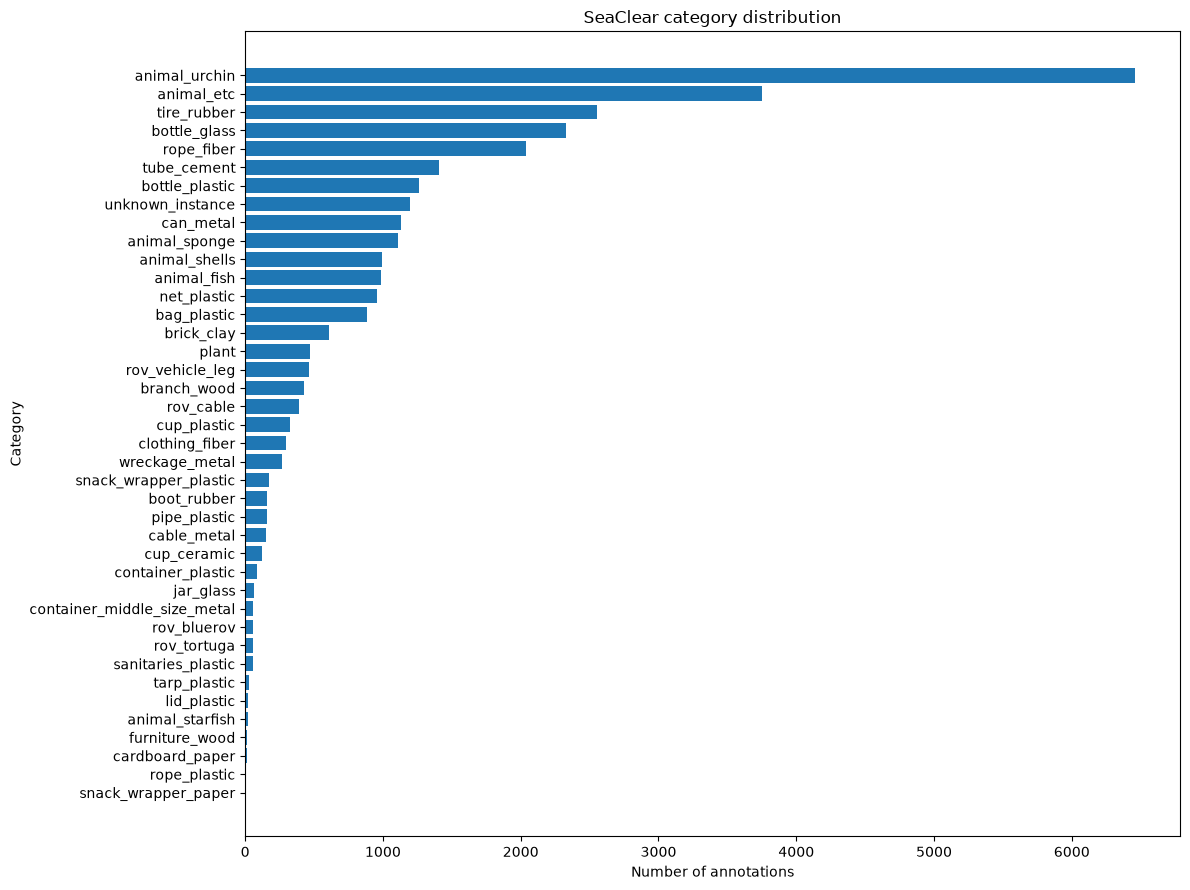

In [4]:
category_counts = Counter(annotation["category_id"] for annotation in data["annotations"])

category_distribution = pd.DataFrame([
    {
        "Category": category_map[category_id],
        "Annotation_Count": category_counts.get(category_id, 0)
    }
    for category_id in category_map
]).sort_values("Annotation_Count", ascending=False).reset_index(drop=True)

display(category_distribution)

plt.figure(figsize=(12, 9))
plot_data = category_distribution.sort_values("Annotation_Count")
plt.barh(plot_data["Category"], plot_data["Annotation_Count"])
plt.xlabel("Number of annotations")
plt.ylabel("Category")
plt.title("SeaClear category distribution")
plt.tight_layout()
plt.show()

## 6. Explore collection locations and cameras

The original image directory structure stores images by site and camera. The following analysis summarizes the image and annotation counts by location, and the number of images collected by each camera at each site.

In [5]:
image_location = {}
image_camera = {}

for image_info in data["images"]:
    image_path = image_map[image_info["file_name"]][0]
    image_location[image_info["id"]] = image_path.parent.parent.name
    image_camera[image_info["id"]] = image_path.parent.name

image_counts = Counter(image_location.values())
annotation_counts_by_location = Counter(
    image_location[annotation["image_id"]]
    for annotation in data["annotations"]
)

location_summary = pd.DataFrame([
    {
        "Location": location,
        "Total_Images": image_counts[location],
        "Total_Annotations": annotation_counts_by_location[location]
    }
    for location in sorted(image_counts)
])

display(location_summary)

camera_distribution = pd.DataFrame([
    {
        "Image_ID": image_info["id"],
        "Location": image_location[image_info["id"]],
        "Camera": image_camera[image_info["id"]]
    }
    for image_info in data["images"]
])

camera_summary = (
    camera_distribution.groupby(["Location", "Camera"])["Image_ID"]
    .nunique().reset_index(name="Total_Images")
)
display(camera_summary)

,Location,Total_Images,Total_Annotations
0,Bistrina,3652,21264
1,Jakljan,306,957
2,Lokrum,972,4084
3,Marseille,3441,4094
4,Slano,239,1156


,Location,Camera,Total_Images
0,Bistrina,Bluerobotics HD,1390
1,Bistrina,Paralenz Vaquita Gen 2,2069
2,Bistrina,SIP-E323CV,193
3,Jakljan,Bluerobotics HD,241
4,Jakljan,Paralenz Vaquita,65
5,Lokrum,Bluerobotics HD,556
6,Lokrum,Paralenz Vaquita Gen 2,77
7,Lokrum,SIP-E323CV,339
8,Marseille,SIP-E323CV,3441
9,Slano,Bluerobotics HD,168


## 7. Analyze category coverage across locations and cameras

This section checks how many unique images, locations, and camera groups contain each category. It was used to help choose categories with meaningful representation across the dataset.

In [6]:
annotation_details = pd.DataFrame([
    {
        "Image_ID": annotation["image_id"],
        "Location": image_location[annotation["image_id"]],
        "Camera": image_camera[annotation["image_id"]],
        "Category": category_map[annotation["category_id"]]
    }
    for annotation in data["annotations"]
])

annotation_details["Location_Camera"] = (
    annotation_details["Location"] + " | " + annotation_details["Camera"]
)

category_analysis = pd.DataFrame({
    "Unique_Images": annotation_details.groupby("Category")["Image_ID"].nunique(),
    "Camera_Coverage": annotation_details.groupby("Category")["Location_Camera"].nunique(),
    "Location_Coverage": annotation_details.groupby("Category")["Location"].nunique()
}).reset_index().sort_values("Unique_Images", ascending=False)

display(category_analysis)
category_analysis.to_csv(RESULTS_DIR / "category_candidate_analysis.csv", index=False)

,Category,Unique_Images,Camera_Coverage,Location_Coverage
36,tire_rubber,2260,8,5
0,animal_etc,2007,6,4
5,animal_urchin,1999,6,4
26,rope_fiber,1356,7,4
8,bottle_glass,1355,8,4
37,tube_cement,1139,6,4
9,bottle_plastic,1127,10,5
23,net_plastic,900,3,1
38,unknown_instance,884,8,4
6,bag_plastic,852,7,3


## 8. Select the 12 project categories

The project uses the following 12 categories. Faster R-CNN reserves label `0` for background, so the model prediction head contains 13 classes in total.

In [7]:
selected_categories = [
    "bottle_plastic",
    "bottle_glass",
    "can_metal",
    "bag_plastic",
    "tire_rubber",
    "tube_cement",
    "clothing_fiber",
    "cup_plastic",
    "animal_urchin",
    "animal_etc",
    "animal_sponge",
    "animal_shells"
]

selected_analysis = category_analysis[
    category_analysis["Category"].isin(selected_categories)
].copy()

display(selected_analysis)
print("Selected categories:", len(selected_categories))

,Category,Unique_Images,Camera_Coverage,Location_Coverage
36,tire_rubber,2260,8,5
0,animal_etc,2007,6,4
5,animal_urchin,1999,6,4
8,bottle_glass,1355,8,4
37,tube_cement,1139,6,4
9,bottle_plastic,1127,10,5
6,bag_plastic,852,7,3
13,can_metal,811,9,4
3,animal_sponge,731,4,2
2,animal_shells,523,5,3


Selected categories: 12


## 9. Inspect sample annotations and validate bounding boxes

COCO bounding boxes are stored as `[x, y, width, height]`. Faster R-CNN expects `[x1, y1, x2, y2]`. This section checks the selected annotations and displays a sample image with its ground-truth boxes.

In [8]:
selected_annotations = [
    annotation for annotation in data["annotations"]
    if category_map[annotation["category_id"]] in selected_categories
]

image_dimensions = {
    image_info["id"]: (image_info["width"], image_info["height"])
    for image_info in data["images"]
}

invalid_boxes = []
for annotation in selected_annotations:
    x, y, width, height = annotation["bbox"]
    image_width, image_height = image_dimensions[annotation["image_id"]]
    if (width <= 0 or height <= 0 or x < 0 or y < 0 or
        x + width > image_width or y + height > image_height):
        invalid_boxes.append(annotation)

print("Selected annotations:", len(selected_annotations))
print("Invalid selected bounding boxes:", len(invalid_boxes))

Selected annotations: 22507
Invalid selected bounding boxes: 0


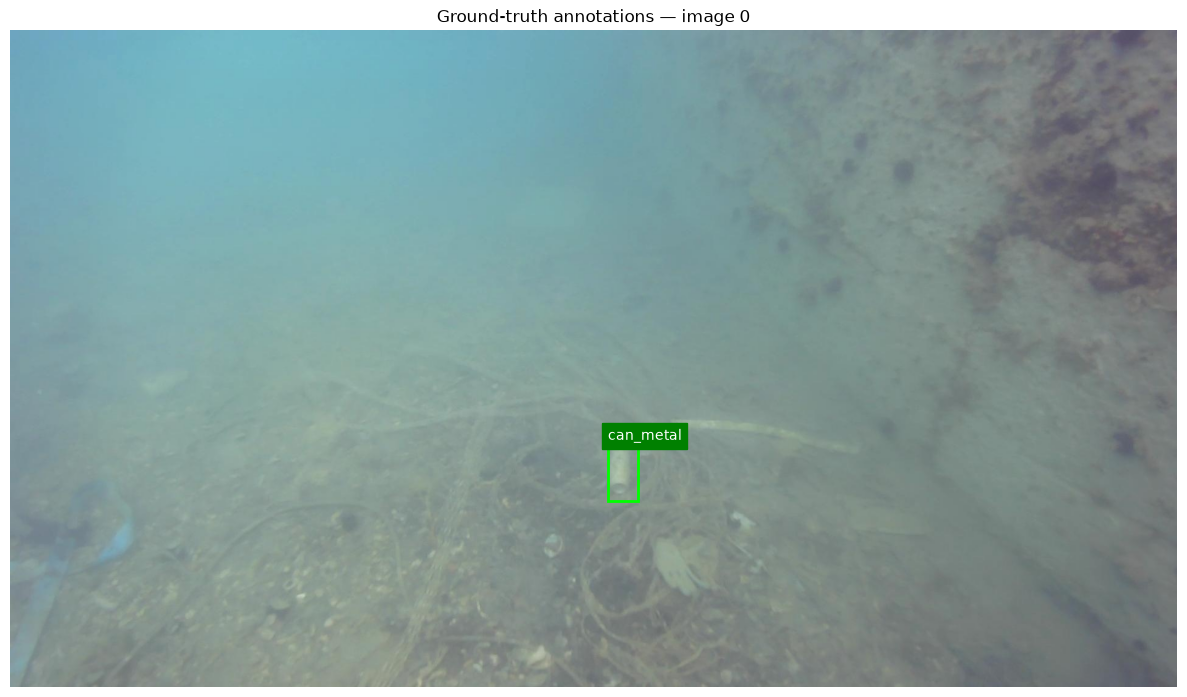

In [9]:
# Display one annotated image from the selected categories.
selected_image_ids = sorted({ann["image_id"] for ann in selected_annotations})
example_image_id = selected_image_ids[0]
example_info = next(img for img in data["images"] if img["id"] == example_image_id)
example_path = image_map[example_info["file_name"]][0]
example_image = Image.open(example_path).convert("RGB")

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(example_image)
for ann in selected_annotations:
    if ann["image_id"] == example_image_id:
        x, y, width, height = ann["bbox"]
        rect = patches.Rectangle(
            (x, y), width, height, linewidth=2,
            edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x, y, category_map[ann["category_id"]],
                color="white", backgroundcolor="green")
ax.set_title(f"Ground-truth annotations — image {example_image_id}")
ax.axis("off")
plt.tight_layout()
plt.show()

## 10. Prepare class IDs and the original data split

Only annotations from the 12 selected categories are retained. The class mapping is sorted alphabetically and maps the selected object categories to labels 1–12. The existing train/validation/test split is loaded from `results/dataset_split.json` to preserve the same split used during training.

In [10]:
if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        f"Could not find the saved split file: {SPLIT_PATH}. "
        "The original dataset_split.json is required to reproduce the final evaluation."
    )

with open(SPLIT_PATH, "r", encoding="utf-8") as file:
    split_data = json.load(file)

class_mapping = {name: index + 1 for index, name in enumerate(sorted(selected_categories))}
original_to_new = {
    category_id: class_mapping[name]
    for category_id, name in category_map.items()
    if name in class_mapping
}

filtered_annotations = [
    ann for ann in data["annotations"]
    if ann["category_id"] in original_to_new
]

image_records = {image_info["id"]: image_info for image_info in data["images"]}
selected_image_id_set = {ann["image_id"] for ann in filtered_annotations}

split_image_ids = {
    split_name: [image_id for image_id in split_data[split_name]
                 if image_id in selected_image_id_set]
    for split_name in ["train", "validation", "test"]
}

all_split_ids = sum(split_image_ids.values(), [])
if len(all_split_ids) != len(set(all_split_ids)):
    raise ValueError("Train, validation, and test splits overlap.")

print("Class mapping:", class_mapping)
print("Selected annotations:", len(filtered_annotations))
for split_name, ids in split_image_ids.items():
    print(f"{split_name}: {len(ids)} images")

Class mapping: {'animal_etc': 1, 'animal_shells': 2, 'animal_sponge': 3, 'animal_urchin': 4, 'bag_plastic': 5, 'bottle_glass': 6, 'bottle_plastic': 7, 'can_metal': 8, 'clothing_fiber': 9, 'cup_plastic': 10, 'tire_rubber': 11, 'tube_cement': 12}
Selected annotations: 22507
train: 5520 images
validation: 1183 images
test: 1184 images


## 11. Group annotations and create the PyTorch dataset

The bounding boxes are converted into `xyxy` format and grouped by image ID. The custom dataset returns an image tensor and its object boxes and labels.

In [11]:
grouped_annotations = defaultdict(lambda: {"boxes": [], "labels": []})

for ann in filtered_annotations:
    x, y, width, height = ann["bbox"]
    if width <= 0 or height <= 0:
        continue
    grouped_annotations[ann["image_id"]]["boxes"].append(
        [x, y, x + width, y + height]
    )
    grouped_annotations[ann["image_id"]]["labels"].append(
        original_to_new[ann["category_id"]]
    )

class MarineDataset(Dataset):
    def __init__(self, image_ids, grouped_annotations, image_records, image_map):
        self.image_ids = list(image_ids)
        self.grouped_annotations = grouped_annotations
        self.image_records = image_records
        self.image_map = image_map

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image_info = self.image_records[image_id]
        image_path = self.image_map[image_info["file_name"]][0]
        image = Image.open(image_path).convert("RGB")
        annotation = self.grouped_annotations[image_id]

        boxes = torch.tensor(annotation["boxes"], dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(annotation["labels"], dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([image_id], dtype=torch.int64)
        }
        return F.to_tensor(image), target


def collate_fn(batch):
    return tuple(zip(*batch))

train_dataset = MarineDataset(
    split_image_ids["train"], grouped_annotations, image_records, image_map
)
val_dataset = MarineDataset(
    split_image_ids["validation"], grouped_annotations, image_records, image_map
)
test_dataset = MarineDataset(
    split_image_ids["test"], grouped_annotations, image_records, image_map
)

train_loader = DataLoader(
    train_dataset, batch_size=1, shuffle=True, num_workers=0,
    pin_memory=torch.cuda.is_available(), collate_fn=collate_fn
)
val_loader = DataLoader(
    val_dataset, batch_size=1, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), collate_fn=collate_fn
)
test_loader = DataLoader(
    test_dataset, batch_size=1, shuffle=False, num_workers=0,
    pin_memory=torch.cuda.is_available(), collate_fn=collate_fn
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 5520
Validation images: 1183
Test images: 1184


## 12. Faster R-CNN model architecture

The project uses Faster R-CNN with a ResNet-50 Feature Pyramid Network (FPN) backbone. The model starts from TorchVision COCO-pretrained weights and replaces the original prediction head with a 13-class head: 12 project categories plus background.

The model was fine-tuned locally using a batch size of 1 to fit the available GPU memory. The saved checkpoint contains the trained weights and the resize settings used during training.

In [12]:
NUM_CLASSES = len(class_mapping) + 1  # 12 object classes + background

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

if device.type != "cuda":
    raise RuntimeError(
        "CUDA GPU was not detected. Please run this notebook on the computer "
        "with the NVIDIA GPU so the 22-epoch training can run as planned."
    )

print("GPU:", torch.cuda.get_device_name(0))

# Start from COCO-pretrained Faster R-CNN weights.
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights)

# Replace the COCO prediction head with the 12 project classes + background.
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

# Use the image size settings selected for the available GPU memory.
model.transform.min_size = (400,)
model.transform.max_size = 600

model.to(device)

idx_to_class = {label: name for name, label in class_mapping.items()}

print("Fresh Faster R-CNN ResNet-50 FPN initialized.")
print("COCO pretrained weights:", True)
print("Number of model classes:", NUM_CLASSES)
print("Custom MarineVision checkpoint loaded:", False)


Selected device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\DELL/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:03<00:00, 45.6MB/s] 


Fresh Faster R-CNN ResNet-50 FPN initialized.
COCO pretrained weights: True
Number of model classes: 13
Custom MarineVision checkpoint loaded: False


## 13. Training configuration and training functions

The detector is fine-tuned for 22 consecutive epochs using the training split. After each epoch, the model is evaluated on the validation split. The latest checkpoint is saved after every epoch, and the checkpoint with the lowest validation loss is also saved separately.

The training run uses SGD, momentum, weight decay, a StepLR learning-rate scheduler, batch size 1, and mixed-precision training on the CUDA GPU.

In [13]:
# Training configuration
EPOCHS = 22
LEARNING_RATE = 0.001
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
BATCH_SIZE = 1

optimizer = torch.optim.SGD(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer, step_size=5, gamma=0.1
)

scaler = torch.amp.GradScaler("cuda")

HISTORY_PATH = RUN_DIR / "training_history.csv"
LATEST_CHECKPOINT_PATH = RUN_DIR / "marinevision_latest.pth"
BEST_CHECKPOINT_PATH = RUN_DIR / "marinevision_best_val_loss.pth"

print("Epochs:", EPOCHS)
print("Optimizer: SGD")
print("Learning rate:", LEARNING_RATE)
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler: StepLR (step_size=5, gamma=0.1)")
print("Batch size:", BATCH_SIZE)
print("Checkpoint folder:", RUN_DIR)


Epochs: 22
Optimizer: SGD
Learning rate: 0.001
Momentum: 0.9
Weight decay: 0.0005
Scheduler: StepLR (step_size=5, gamma=0.1)
Batch size: 1
Checkpoint folder: E:\MarineVision_AI\models\fresh_22_epochs


In [14]:
def train_one_epoch(model, optimizer, loader, scaler, device):
    model.train()
    total_loss = 0.0

    for images, targets in tqdm(loader, desc="Training batches", dynamic_ncols=True):
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

        if not torch.isfinite(losses):
            raise RuntimeError("Non-finite training loss detected.")

        scaler.scale(losses).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += losses.detach().item()

    return total_loss / max(len(loader), 1)


def validate_one_epoch(model, loader, device):
    # TorchVision detection models return loss dictionaries in training mode.
    model.train()

    # Keep BatchNorm layers in evaluation mode while calculating validation loss.
    for layer in model.modules():
        if isinstance(layer, torch.nn.modules.batchnorm._BatchNorm):
            layer.eval()

    total_loss = 0.0

    with torch.no_grad():
        for images, targets in tqdm(loader, desc="Validation batches", dynamic_ncols=True):
            images = [image.to(device) for image in images]
            targets = [
                {key: value.to(device) for key, value in target.items()}
                for target in targets
            ]

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                loss_dict = model(images, targets)
                losses = sum(loss for loss in loss_dict.values())

            total_loss += losses.item()

    model.eval()
    return total_loss / max(len(loader), 1)


### Run the complete training process: Epoch 1 to Epoch 22

This is one continuous training loop. The model is not resumed from the earlier Epoch 9 checkpoint. The training and validation losses, learning rate, and epoch time are recorded after every epoch. A checkpoint is saved after each epoch so the progress is preserved if the computer is interrupted.

Validation batches: 100%|██████████| 1183/1183 [01:57<00:00, 10.08it/s]


Epoch 01/22 | Train Loss: 0.4635 | Validation Loss: 0.3635 | Learning Rate: 0.001000 | Time: 17.17 min


Validation batches: 100%|██████████| 1183/1183 [01:54<00:00, 10.29it/s]


Epoch 02/22 | Train Loss: 0.3329 | Validation Loss: 0.3137 | Learning Rate: 0.001000 | Time: 16.63 min


Validation batches: 100%|██████████| 1183/1183 [01:54<00:00, 10.29it/s]


Epoch 03/22 | Train Loss: 0.2838 | Validation Loss: 0.2995 | Learning Rate: 0.001000 | Time: 16.64 min


... (35 outputs left out)

Epoch 21/22 | Train Loss: 0.1299 | Validation Loss: 0.2565 | Learning Rate: 0.000000 | Time: 16.61 min


Validation batches: 100%|██████████| 1183/1183 [01:55<00:00, 10.28it/s]


Epoch 22/22 | Train Loss: 0.1298 | Validation Loss: 0.2570 | Learning Rate: 0.000000 | Time: 16.57 min

Training completed.
Total training time: 6.11 hours
Training history saved to: E:\MarineVision_AI\models\fresh_22_epochs\training_history.csv
Latest checkpoint saved to: E:\MarineVision_AI\models\fresh_22_epochs\marinevision_latest.pth
Best checkpoint saved to: E:\MarineVision_AI\models\fresh_22_epochs\marinevision_best_val_loss.pth


,epoch,train_loss,val_loss,learning_rate,epoch_time_seconds
0,1,0.463462,0.363481,1.000000e-03,1030.204052
1,2,0.332908,0.313715,1.000000e-03,997.749542
2,3,0.283807,0.299457,1.000000e-03,998.528085
3,4,0.254208,0.285116,1.000000e-03,998.842748
4,5,0.234357,0.251156,1.000000e-03,1000.136424
5,6,0.171384,0.245424,1.000000e-04,982.493040
6,7,0.158536,0.243850,1.000000e-04,990.161170
7,8,0.150562,0.251453,1.000000e-04,992.524871
8,9,0.145616,0.245356,1.000000e-04,990.329289
9,10,0.140808,0.249592,1.000000e-04,984.901819


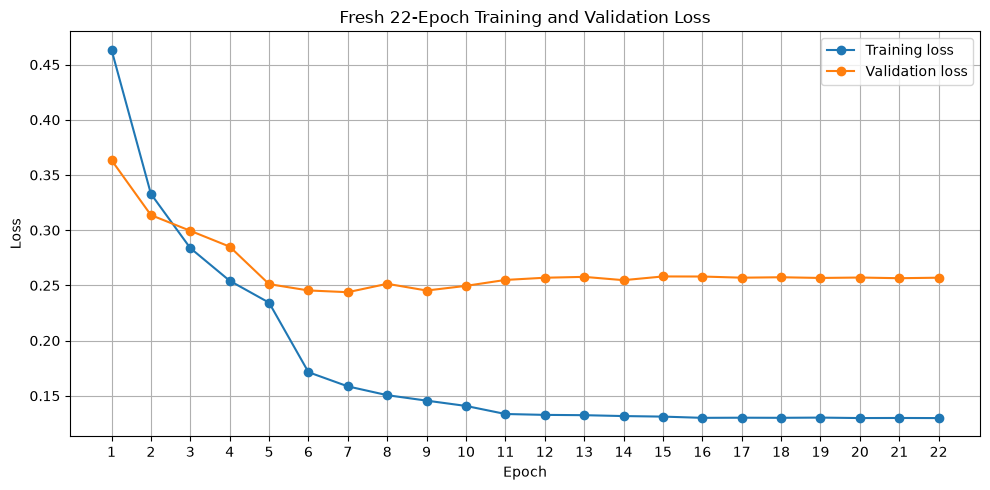

In [15]:
# Start a fresh 22-epoch run.
# This cell intentionally does not load any previous MarineVision checkpoint.

training_history = []
best_val_loss = float("inf")

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_loss = train_one_epoch(
        model, optimizer, train_loader, scaler, device
    )

    val_loss = validate_one_epoch(
        model, val_loader, device
    )

    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    epoch_time = time.time() - epoch_start

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    }
    training_history.append(row)

    # Save the full training history after every epoch.
    pd.DataFrame(training_history).to_csv(HISTORY_PATH, index=False)

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "train_loss": train_loss,
        "val_loss": val_loss,
        "class_mapping": class_mapping,
        "min_size": model.transform.min_size,
        "max_size": model.transform.max_size
    }

    # Keep the latest checkpoint so progress is preserved.
    torch.save(checkpoint, LATEST_CHECKPOINT_PATH)

    # Keep the checkpoint with the lowest validation loss.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(checkpoint, BEST_CHECKPOINT_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Learning Rate: {current_lr:.6f} | "
        f"Time: {epoch_time / 60:.2f} min"
    )

total_training_time = time.time() - start_time

print("\nTraining completed.")
print(f"Total training time: {total_training_time / 3600:.2f} hours")
print("Training history saved to:", HISTORY_PATH)
print("Latest checkpoint saved to:", LATEST_CHECKPOINT_PATH)
print("Best checkpoint saved to:", BEST_CHECKPOINT_PATH)

training_history_df = pd.DataFrame(training_history)
display(training_history_df)

plt.figure(figsize=(10, 5))
plt.plot(training_history_df["epoch"], training_history_df["train_loss"],
         marker="o", label="Training loss")
plt.plot(training_history_df["epoch"], training_history_df["val_loss"],
         marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Fresh 22-Epoch Training and Validation Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 14. Load the best checkpoint from the fresh 22-epoch run

After the training loop finishes, load the checkpoint with the lowest validation loss. This is the newly trained MarineVision model used for the following evaluation and detection sections.

In [16]:
if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        "The fresh training checkpoint was not found. Run the 22-epoch "
        "training cell before continuing."
    )

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

if "min_size" in checkpoint:
    model.transform.min_size = checkpoint["min_size"]
if "max_size" in checkpoint:
    model.transform.max_size = checkpoint["max_size"]

model.to(device)
model.eval()

idx_to_class = {label: name for name, label in class_mapping.items()}
confidence_threshold = 0.50

print("Freshly trained model restored successfully.")
print("Checkpoint:", BEST_CHECKPOINT_PATH)
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Validation loss:", round(checkpoint["val_loss"], 4))
print("Model type:", type(model).__name__)
print("Evaluation mode:", not model.training)
print("Classes:", NUM_CLASSES)


Freshly trained model restored successfully.
Checkpoint: E:\MarineVision_AI\models\fresh_22_epochs\marinevision_best_val_loss.pth
Best checkpoint epoch: 7
Validation loss: 0.2438
Model type: FasterRCNN
Evaluation mode: True
Classes: 13


## 15. Model evaluation: mAP and recall

The final model was evaluated using TorchMetrics `MeanAveragePrecision` with bounding boxes in `xyxy` format. Predictions are passed to the metric without applying the visualization confidence threshold. The validation and test sets are evaluated separately; the held-out test set is reserved for final evaluation.

In [17]:
from torchmetrics.detection import MeanAveragePrecision

def evaluate_map(model, loader, device):
    model.eval()
    metric = MeanAveragePrecision(
        box_format="xyxy", iou_type="bbox", class_metrics=True
    )

    with torch.no_grad():
        for images, targets in tqdm(loader, desc="Evaluating", dynamic_ncols=True):
            images = [image.to(device) for image in images]
            predictions = model(images)

            predictions = [{
                "boxes": prediction["boxes"].detach().cpu(),
                "scores": prediction["scores"].detach().cpu(),
                "labels": prediction["labels"].detach().cpu()
            } for prediction in predictions]

            targets = [{
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu()
            } for target in targets]

            metric.update(predictions, targets)

    return metric.compute()

### Evaluation results from the fresh training run

The following cell calculates metrics using the newly trained best checkpoint. These results are generated when the notebook is executed; the earlier experiment's metric values are not copied into this report.

In [18]:
# Evaluate both splits using the newly trained best checkpoint.
validation_metrics = evaluate_map(model, val_loader, device)
test_metrics = evaluate_map(model, test_loader, device)

evaluation_summary = pd.DataFrame([
    {
        "Split": "Validation",
        "Images": len(val_dataset),
        "mAP": validation_metrics["map"].item(),
        "mAP50": validation_metrics["map_50"].item(),
        "mAP75": validation_metrics["map_75"].item(),
        "mAR100": validation_metrics["mar_100"].item()
    },
    {
        "Split": "Test",
        "Images": len(test_dataset),
        "mAP": test_metrics["map"].item(),
        "mAP50": test_metrics["map_50"].item(),
        "mAP75": test_metrics["map_75"].item(),
        "mAR100": test_metrics["mar_100"].item()
    }
])

display(evaluation_summary)
evaluation_summary.to_csv(
    RESULTS_DIR / "marinevision_fresh_22_epoch_metrics.csv",
    index=False
)
print("Fresh evaluation metrics saved.")


Evaluating: 100%|██████████| 1184/1184 [02:03<00:00,  9.60it/s]


,Split,Images,mAP,mAP50,mAP75,mAR100
0,Validation,1183,0.578820,0.821751,0.657967,0.659661
1,Test,1184,0.570006,0.821265,0.652933,0.649718


Fresh evaluation metrics saved.


## 16. Example object detection and visualization

The detector predicts bounding boxes, labels, and confidence scores. A confidence threshold is used for displaying predictions. NMS is then applied to remove highly overlapping duplicate boxes.

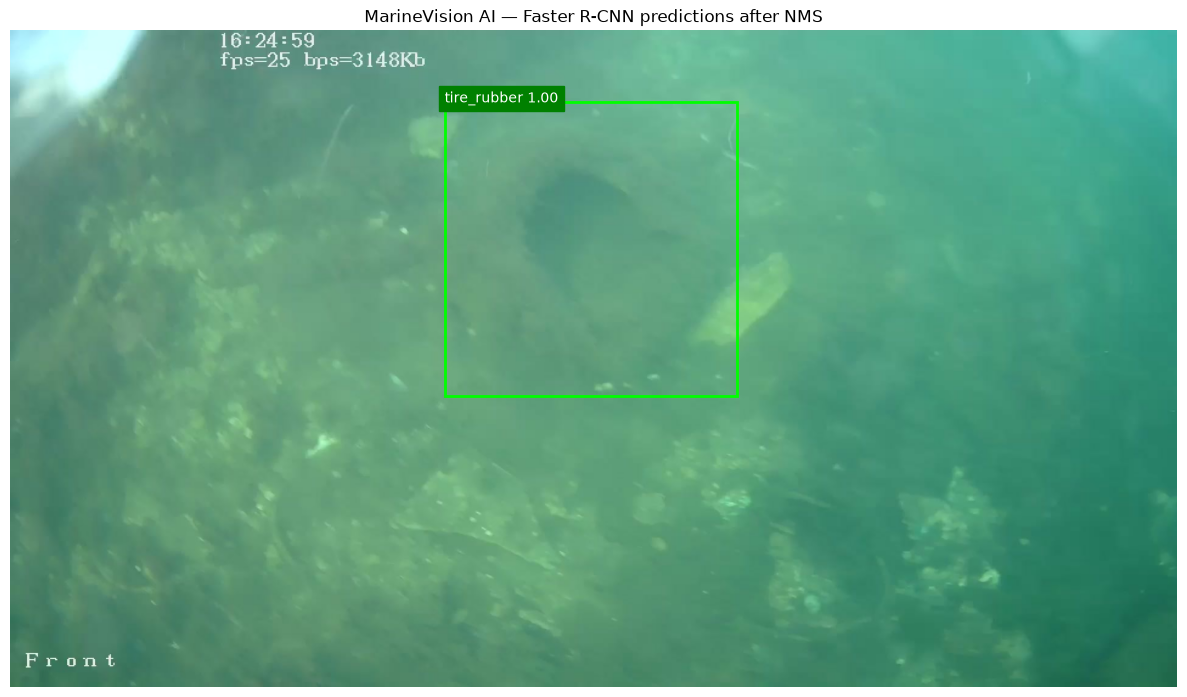

Detections after NMS: 1


,object,confidence,box_xyxy
0,tire_rubber,0.9989,"[714.44, 117.94, 1195.86, 600.81]"


In [19]:
def detect_marine_objects(image, confidence_threshold=0.50, iou_threshold=0.30):
    model.eval()
    with torch.no_grad():
        prediction = model([image.to(device)])[0]

    boxes = prediction["boxes"].detach().cpu()
    scores = prediction["scores"].detach().cpu()
    labels = prediction["labels"].detach().cpu()

    valid = scores >= confidence_threshold
    boxes = boxes[valid]
    scores = scores[valid]
    labels = labels[valid]

    if len(boxes) > 0:
        keep = nms(boxes, scores, iou_threshold=iou_threshold)
        boxes = boxes[keep]
        scores = scores[keep]
        labels = labels[keep]

    detections = []
    for label, score, box in zip(labels, scores, boxes):
        detections.append({
            "object": idx_to_class.get(label.item(), "Unknown"),
            "confidence": round(score.item(), 4),
            "box_xyxy": [round(value, 2) for value in box.tolist()]
        })

    return detections, prediction


# Show one test image and its model predictions.
example_test_image, example_test_target = test_dataset[0]
example_detections, example_prediction = detect_marine_objects(
    example_test_image, confidence_threshold=confidence_threshold
)

image_display = example_test_image.permute(1, 2, 0).cpu().numpy()
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(image_display)

for detection in example_detections:
    x1, y1, x2, y2 = detection["box_xyxy"]
    rect = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor="lime", facecolor="none"
    )
    ax.add_patch(rect)
    ax.text(
        x1, y1,
        f"{detection['object']} {detection['confidence']:.2f}",
        color="white", backgroundcolor="green"
    )

ax.set_title("MarineVision AI — Faster R-CNN predictions after NMS")
ax.axis("off")
plt.tight_layout()
plt.show()
print("Detections after NMS:", len(example_detections))
display(pd.DataFrame(example_detections))

## 17. Twenty-image experiment

A fixed random seed was used to select 20 test-set indices. The selected indices were:

`[228, 51, 563, 501, 457, 285, 209, 1116, 178, 864, 65, 61, 191, 447, 476, 1034, 54, 1149, 407, 859]`

The experiment ran Faster R-CNN detection followed by Groq vision analysis for each selected image. The recorded run completed **20 of 20 images successfully**, with **0 failures**. The combined output file is `results/marinevision_groq_20_image_results.json`.

## 18. OpenRouter Vision Integration
The OpenRouter vision model receives the underwater image and Faster R-CNN predictions. It generates an environmental report covering visible objects, environmental observations, potential impacts, marine risks, cleanup recommendations, and an overall assessment.

In [31]:
def analyze_with_openrouter(image, detected_objects):
    # Convert the PyTorch image tensor to a smaller JPEG to reduce request size.
    from torchvision.transforms.functional import to_pil_image

    pil_image = to_pil_image(image.detach().cpu()).convert("RGB")
    pil_image.thumbnail((1024, 1024))
    buffer = io.BytesIO()
    pil_image.save(buffer, format="JPEG", quality=85)
    base64_image = base64.b64encode(buffer.getvalue()).decode("utf-8")

    if detected_objects:
        objects_text = "\\n".join(
            f"- {item['object']} (detector confidence: {item['confidence']})"
            for item in detected_objects
        )
    else:
        objects_text = "No objects were detected above the detector confidence threshold."

    prompt = f"""You are an assistant supporting underwater marine debris assessment.
The Faster R-CNN detector produced these predictions:
{objects_text}

Study the attached underwater image and return a concise environmental analysis.
Use these headings:
1. Visible objects
2. Environmental observations
3. Potential environmental impacts
4. Possible marine risks
5. Suggested cleanup or monitoring actions
6. Overall assessment

Only describe what is visually supported. Separate visible evidence from possibilities.
Do not claim that chemical contamination is confirmed. Do not treat detector confidence
as proof of certainty. If no debris is visibly supported, say so."""

    payload = {
        "model": OPENROUTER_MODEL,
        "messages": [{
            "role": "user",
            "content": [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {
                    "url": f"data:image/jpeg;base64,{base64_image}"
                }}
            ]
        }],
        "temperature": 0.2,
        "max_tokens": 900,
        "reasoning": {"enabled": False}
    }

    response = requests.post(
        OPENROUTER_API_URL,
        headers=openrouter_headers,
        json=payload,
        timeout=180
    )
    response.raise_for_status()
    response_data = response.json()
    return response_data["choices"][0]["message"]["content"]


def process_marine_image_openrouter(image_index):
    start_time = time.time()
    image, target = test_dataset[image_index]
    detections, prediction = detect_marine_objects(image)

    analysis_text = analyze_with_openrouter(image, detections)

    return {
        "image_index": image_index,
        "ai_provider": "OpenRouter",
        "ai_model": OPENROUTER_MODEL,
        "detections": detections,
        "environmental_analysis": analysis_text,
        "processing_time_seconds": round(time.time() - start_time, 2)
    }

print("OpenRouter image-analysis functions are ready.")

OpenRouter image-analysis functions are ready.


## 19. Run and Save the OpenRouter 20-Image Experiment
The OpenRouter model analyzes 20 selected test images. The results and any failed requests are saved in a JSON file for further review and evaluation

In [32]:
OPENROUTER_TEST_INDICES = [
    228, 51, 563, 501, 457,
    285, 209, 1116, 178, 864,
    65, 61, 191, 447, 476,
    1034, 54, 1149, 407, 859
]

RUN_OPENROUTER_BATCH = True

if RUN_OPENROUTER_BATCH:
    openrouter_results = []
    openrouter_failures = []

    for position, image_index in enumerate(OPENROUTER_TEST_INDICES, start=1):
        print(f"Processing image {position}/20 (index {image_index})...")
        try:
            result = process_marine_image_openrouter(image_index)
            openrouter_results.append(result)
            print(f"SUCCESS — image {image_index} — {result['processing_time_seconds']} sec")
            print(result["environmental_analysis"][:700])
        except Exception as error:
            openrouter_failures.append({
                "image_index": image_index,
                "error": str(error)
            })
            print(f"FAILED — image {image_index}: {error}")

        # Small pause to reduce the chance of hitting per-minute limits.
        time.sleep(3)

    openrouter_batch_data = {
        "project": "MarineVision AI",
        "provider": "OpenRouter",
        "model": OPENROUTER_MODEL,
        "total_images": len(OPENROUTER_TEST_INDICES),
        "successful_images": len(openrouter_results),
        "failed_images": len(openrouter_failures),
        "results": openrouter_results,
        "errors": openrouter_failures
    }

    OPENROUTER_RESULTS_PATH = RESULTS_DIR / "marinevision_openrouter_20_image_results.json"
    with open(OPENROUTER_RESULTS_PATH, "w", encoding="utf-8") as file:
        json.dump(openrouter_batch_data, file, indent=4, ensure_ascii=False)

    print("\\n" + "=" * 55)
    print("OPENROUTER 20-IMAGE EXPERIMENT")
    print("=" * 55)
    print("Successful:", len(openrouter_results))
    print("Failed:", len(openrouter_failures))
    print("Saved results:", OPENROUTER_RESULTS_PATH)
else:
    print("OpenRouter batch disabled.")

Processing image 1/20 (index 228)...
SUCCESS — image 228 — 4.51 sec
1. Visible objects  
- A small, vertically oriented, light-colored cylindrical object is visible near the center-left of the frame, resting on or just above the seabed. It resembles a bottle or container but is too small and indistinct to confirm material or exact identity from this image alone.  
- The detector label “can_metal” is a model prediction, not visually confirmed evidence.

2. Environmental observations  
- Water is turbid with a greenish-blue tint; visibility is limited.  
- Seabed appears to be sand or sediment with some darker patches that may be vegetation or shadow.  
- No other distinct objects, marine life, or debris are clearly visible.

3. Potential environmental impacts
Processing image 2/20 (index 51)...
SUCCESS — image 51 — 4.49 sec
1. Visible objects  
- Seafloor composed of rocks, pebbles, and sediment.  
- Small suspended particles in the water column.  
- No clearly identifiable clothing fib

## 20. Final project summary and limitations

This notebook presents the complete MarineVision AI workflow, from SeaClear dataset exploration and annotation preprocessing to a fresh, continuous 22-epoch Faster R-CNN training run and final evaluation.

The final reported training losses and detection metrics are generated by running the notebook on the local project dataset and CUDA GPU. The model is fine-tuned from COCO-pretrained weights; the earlier custom MarineVision checkpoint is not used to initialize this run.

The project focuses on 12 selected object categories from the original 40-category dataset. Detection quality can vary by category, object size, image visibility, and class imbalance. The AI-generated environmental report is an additional interpretation of image content and model detections; it should not be treated as a substitute for expert environmental assessment.

Before printing the notebook, run all cells from top to bottom and confirm that the training output shows Epoch 01/22 through Epoch 22/22, followed by the fresh validation and test metrics.